In [351]:
import matplotlib.pyplot as plt
import numpy as np

In [368]:
# Define the original sequence
#original_sequence = "PDEAK" #PN3
#original_sequence = "VQAAQAGDTKPIEV" #PN3
original_sequence = "VTDTSGKAGTTKISNV" #PN5
# Define the amino acid categories

amino_acid_categories = {
    'polar': ['N', 'C', 'Q', 'K', 'S', 'T', 'Y'],
    'non-polar': ['A', 'V', 'L', 'I', 'M', 'F', 'P', 'G', 'W'],
    'anionic': ['D', 'E'],
    'cationic': ['R', 'H', 'K']
}

# Define the color map for different amino acid categories
color_map = {
    'polar': '#9467bd',         # Purple
    'non-polar': '#ff7f0e',      # Orange
    'anionic': '#d62728',        # Red
    'cationic': '#2ca02c'        # Green
}

In [369]:
# Create a matrix to store the modified sequences
matrix = np.zeros((len(original_sequence), len(original_sequence)), dtype=object)

# Iterate over each position in the sequence
for i in range(len(original_sequence)):
    # Create a copy of the original sequence
    new_sequence = list(original_sequence)

    # Replace the amino acid at position i with alanine
    if new_sequence[i] != "A":
        new_sequence[i] = "a"
    # Store the modified sequence in the matrix
    matrix[i] = new_sequence


VTDTSGKAGTTKISNV 
aTDTSGKAGTTKISNV V1A
VaDTSGKAGTTKISNV T2A
VTaTSGKAGTTKISNV D3A
VTDaSGKAGTTKISNV T4A
VTDTaGKAGTTKISNV S5A
VTDTSaKAGTTKISNV G6A
VTDTSGaAGTTKISNV K7A
VTDTSGKAaTTKISNV G9A
VTDTSGKAGaTKISNV T10A
VTDTSGKAGTaKISNV T11A
VTDTSGKAGTTaISNV K12A
VTDTSGKAGTTKaSNV I13A
VTDTSGKAGTTKIaNV S14A
VTDTSGKAGTTKISaV N15A
VTDTSGKAGTTKISNa V16A
[('VTDTSGKAGTTKISNV', ''), ('aTDTSGKAGTTKISNV', 'V1A'), ('VaDTSGKAGTTKISNV', 'T2A'), ('VTaTSGKAGTTKISNV', 'D3A'), ('VTDaSGKAGTTKISNV', 'T4A'), ('VTDTaGKAGTTKISNV', 'S5A'), ('VTDTSaKAGTTKISNV', 'G6A'), ('VTDTSGaAGTTKISNV', 'K7A'), ('VTDTSGKAaTTKISNV', 'G9A'), ('VTDTSGKAGaTKISNV', 'T10A'), ('VTDTSGKAGTaKISNV', 'T11A'), ('VTDTSGKAGTTaISNV', 'K12A'), ('VTDTSGKAGTTKaSNV', 'I13A'), ('VTDTSGKAGTTKIaNV', 'S14A'), ('VTDTSGKAGTTKISaV', 'N15A'), ('VTDTSGKAGTTKISNa', 'V16A')]


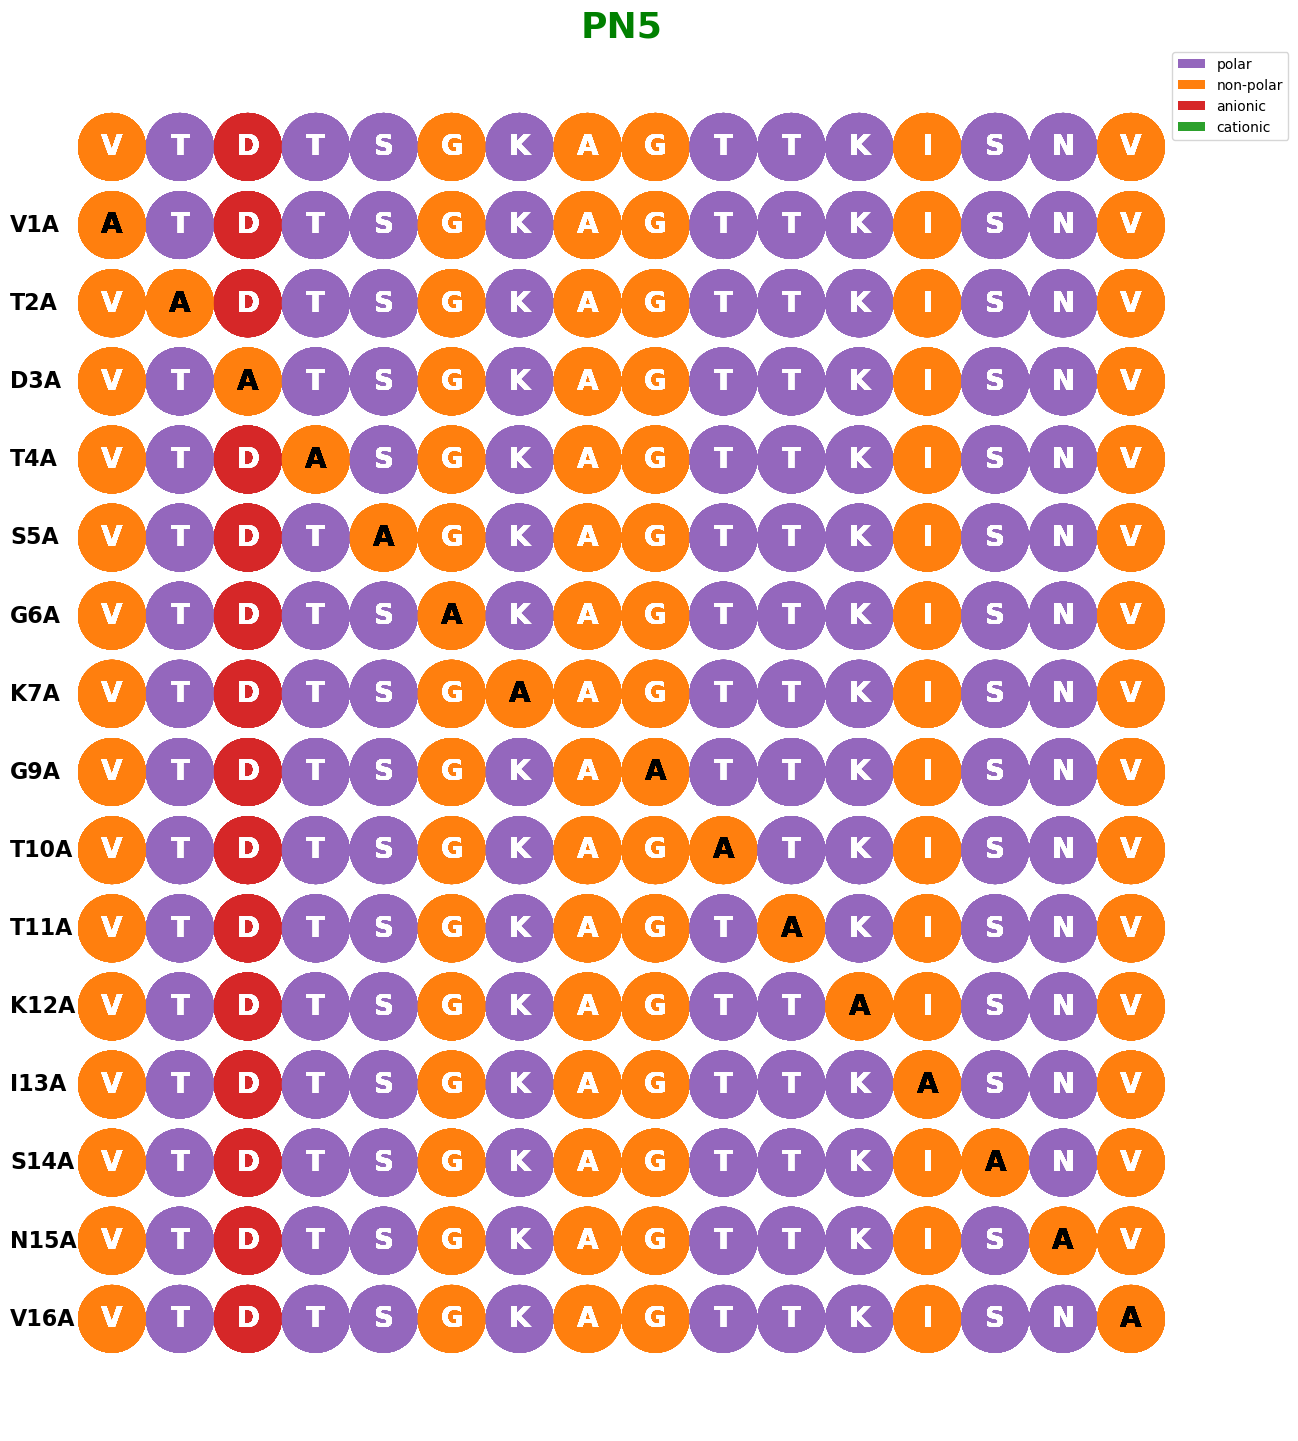

<Figure size 640x480 with 0 Axes>

In [370]:

# Create a list to store the modified sequences and their names
Ala_scan_seq = []

# Add the original sequence to the list
Ala_scan_seq.append((original_sequence, ""))

# Iterate over each position in the sequence
for i, aa in enumerate(original_sequence):
    # Create a copy of the original sequence
    new_sequence = list(original_sequence)

    # Replace the amino acid at position i with alanine
    if aa != "A":
        new_sequence[i] = "a"
        sequence_name = f"{aa}{i+1}A"  # Generate sequence name for the modified sequence
        modified_peptide = ''.join(new_sequence)
        Ala_scan_seq.append((modified_peptide, sequence_name))
        

#Print the Ala_scan_seq list
for sequence, sequence_name in Ala_scan_seq:
    print(sequence, sequence_name)
    
# Print the Ala_scan_seq list
print(Ala_scan_seq)
        

from matplotlib.patches import Patch

# Create a legend for the color representation
legend_elements = [
    Patch(facecolor=color_map['polar'], edgecolor='black', label='Polar'),
    Patch(facecolor=color_map['non-polar'], edgecolor='black', label='Non-polar'),
    Patch(facecolor=color_map['anionic'], edgecolor='black', label='Anionic'),
    Patch(facecolor=color_map['cationic'], edgecolor='black', label='Cationic')
]

# Calculate the maximum sequence length
max_length = max(len(seq) for seq, _ in Ala_scan_seq)


# Create a list to store the circle objects
circles = []


# Iterate over the amino acid sequences
for i, (seq, sequence_name) in enumerate(Ala_scan_seq):
    for j, aa in enumerate(seq):
        # Calculate the x and y positions based on the index
    
        x = (j + 1.5) 
        y = len(Ala_scan_seq) - (i)
        
          # Adjust the vertical spacing between the sequences
        y_spacing = 1.15  # Adjust this value to change the vertical spacing
        y = y * y_spacing
       

        # Calculate the radius based on the grid size
        #Radius of 0.5 will touch each other
        radius = 0.5 # / max(max_length, len(Ala_scan_seq))

        # Get the category of the amino acid
        category = None
        for key, values in amino_acid_categories.items():
            if aa in values:
                category = key
                break

        # Skip the amino acid if no category is found
        if category is None:
            if aa == 'a':
                category = 'non-polar'

        # Get the color for the category
        color = color_map[category]

        # Create the circle object
        circle = plt.Circle((x, y), radius, facecolor=color, label=aa)

        # Add the circle to the list
        circles.append(circle)

# Sort the circles based on radius in descending order
circles.sort(key=lambda c: c.radius, reverse=True)

# Create the figure and axes
ala_seq_length = len(Ala_scan_seq)

fig, ax = plt.subplots(figsize=(max_length+3.5, ala_seq_length+2))


# Add the circles to the plot in the desired order
for i, (seq, sequence_name) in enumerate(Ala_scan_seq):
    for circle in circles:
        ax.add_artist(circle)
        aa = circle.get_label()
        if aa == 'a':
            ax.text(circle.center[0], circle.center[1], f"{aa.capitalize()}", color='black', va='center', ha='center', fontsize=20, weight='bold')
        else:
            ax.text(circle.center[0], circle.center[1], f"{aa}", color='white', va='center', ha='center', fontsize=20, weight='bold')

    # Annotate the sequence name at the top left corner
    if sequence_name:
        y = len(Ala_scan_seq) - i
        y_spacing = 1.15
        y = y * y_spacing
        ax.text(0, y, sequence_name, color='black', va='center', ha='left', fontsize=16, weight='bold')



y_padding = 0.5  # Adjust this value to add padding at the top and bottom
y_min = -y_padding
y_max = 1+len(Ala_scan_seq) * y_spacing + y_padding

plt.xlim(1, max_length+1) #+1 added for accomodating the name 
plt.ylim(y_min, y_max)


# Create the color legend
legend_elements = [Patch(facecolor=color, edgecolor='none', label=category) for category, color in color_map.items()]
legend = ax.legend(handles=legend_elements, loc='upper left', bbox_to_anchor=(1, 1))

# Set the background color of the legend
legend.get_frame().set_facecolor('white')

# Set the aspect ratio to equal
ax.set_aspect('equal')

# Show the plot
ax.axis("off")
ax.grid();
plt.title('PN5',color = "green", fontsize = 26, weight = "bold")
plt.show()
plt.savefig("PN5_Ala_scan.tif",dpi = 600, format = "tif")